# 01 · Data and label

This notebook turns the raw Kaggle CSV into the frozen table every later step reads:

1. explore the raw data (T1.1)
2. keep launch ratings only (T1.2) and remove goalkeepers (T1.3)
3. build the "future elite" label (T1.4 to T1.6)
4. build the temporal, player-grouped split (T1.7)
5. remove leakage columns and fix the candidate feature pool (T1.8, T1.9)
6. save the processed data (T1.10)

The logic lives in `src/data.py`, `src/splits.py` and `src/features.py`; the notebook calls it step by step and checks each step.
Nothing here looks at a model. The design is frozen at the end of this notebook.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd

from src import config, data, splits
from src import features as ft
from src.plotting import BLUE, bar_labels, plt, save, set_style

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
set_style()
config.ensure_dirs()
TABLES = config.RESULTS / "tables"
TABLES.mkdir(exist_ok=True)

## 1. Explore the raw data (T1.1)

In [2]:
raw = data.load_raw()
print("shape:", raw.shape)
raw["fifa_version"].value_counts().sort_index().rename("rows").to_frame().T

shape: (180021, 109)


fifa_version,15,16,17,18,19,20,21,22,23,24
rows,16182,16706,17596,17954,18086,18483,18892,19239,18533,18350


180,021 rows and 109 columns, and all ten versions (FIFA 15 to FC 24) are present, as the plan assumed.
One row is one player in one game version.

The columns fall into a few families:

In [3]:
families = {
    "identifiers and text": [c for c in raw.columns if c in ft.IDENTIFIER_COLS + ft.META_COLS],
    "ratings": ["overall", "potential"],
    "money and reputation": ["value_eur", "wage_eur", "release_clause_eur", "international_reputation"],
    "profile": ["age", "height_cm", "weight_kg", "preferred_foot", "weak_foot", "skill_moves", "league_level"],
    "face stats": ft.FACE_STATS,
    "detailed skills": ft.DETAILED,
    "goalkeeping": ft.GOALKEEPING_COLS,
    "position ratings (text such as '90+3')": ft.POSITION_RATING_COLS,
}
assert sum(len(v) for v in families.values()) == raw.shape[1], "every column should be in exactly one family"
pd.DataFrame({"columns": {k: len(v) for k, v in families.items()},
              "examples": {k: ", ".join(v[:4]) for k, v in families.items()}})

,columns,examples
identifiers and text,28,"player_id, player_url, fifa_version, fifa_update"
ratings,2,"overall, potential"
money and reputation,4,"value_eur, wage_eur, release_clause_eur, inter..."
profile,7,"age, height_cm, weight_kg, preferred_foot"
face stats,6,"pace, shooting, passing, dribbling"
detailed skills,29,"attacking_crossing, attacking_finishing, attac..."
goalkeeping,6,"goalkeeping_diving, goalkeeping_handling, goal..."
position ratings (text such as '90+3'),27,"ls, st, rs, lw"


In [4]:
# Missing values: the 20 emptiest columns
raw.isna().mean().sort_values(ascending=False).head(20).round(3).rename("share missing").to_frame().T

,nation_team_id,nation_position,nation_jersey_number,club_loaned_from,player_tags,goalkeeping_speed,player_traits,release_clause_eur,mentality_composure,shooting,dribbling,pace,passing,defending,physic,club_joined_date,league_level,value_eur,club_jersey_number,club_contract_valid_until_year
share missing,0.944,0.944,0.944,0.94,0.923,0.889,0.546,0.329,0.183,0.111,0.111,0.111,0.111,0.111,0.111,0.07,0.012,0.012,0.01,0.01


In [5]:
# How many updates does each version have, and when were they taken?
raw.groupby("fifa_version").agg(updates=("fifa_update", lambda s: sorted(s.unique())),
                                snapshot_date=("update_as_of", lambda s: sorted(s.unique()))).T

fifa_version,15,16,17,18,19,20,21,22,23,24
updates,[2],[2],[2],[2],[2],[2],[2],[2],[2],[2]
snapshot_date,[2014-09-18],[2015-09-21],[2016-09-20],[2017-09-18],[2018-08-21],[2019-09-19],[2020-09-23],[2021-09-23],[2022-09-26],[2023-09-22]


In [6]:
# Attributes that are empty in some versions
check = ["mentality_composure", "release_clause_eur", "league_level", "pace", "value_eur"]
raw.groupby("fifa_version")[check].apply(lambda g: g.isna().mean()).round(3).T

fifa_version,15,16,17,18,19,20,21,22,23,24
mentality_composure,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
release_clause_eur,1.000,1.000,1.000,0.082,0.070,0.070,0.053,0.061,0.072,0.070
league_level,0.015,0.014,0.013,0.013,0.013,0.034,0.012,0.003,0.004,0.005
pace,0.110,0.109,0.113,0.112,0.112,0.112,0.110,0.111,0.111,0.111
value_eur,0.019,0.018,0.018,0.013,0.013,0.014,0.013,0.004,0.005,0.005


In [7]:
# One young player followed across versions
cols = ["fifa_version", "age", "overall", "potential", "club_name", "league_name", "player_positions"]
raw.loc[raw["short_name"] == "E. Haaland", cols].sort_values("fifa_version").set_index("fifa_version").T

fifa_version,18,19,20,21,22,23,24
age,16,17,18,19,20,21,22
overall,58,67,73,84,88,88,91
potential,78,84,85,92,93,94,94
club_name,Molde,Molde,Salzburg,Borussia Dortmund,Borussia Dortmund,Manchester City,Manchester City
league_name,Eliteserien,Eliteserien,Bundesliga,Bundesliga,Bundesliga,Premier League,Premier League
player_positions,ST,ST,ST,ST,ST,ST,ST


**What one row means.** One row is the launch-day rating card of one player in one game version: his current overall, EA's potential estimate, about 45 skill and physical attributes, and club information.
The same `player_id` appears once per version, so a career can be followed from row to row (Haaland goes from 58 in FIFA 18 to 91 in FC 24).

**Odd things, noted in the decision log:**

* Every version has exactly one update (`fifa_update = 2`), dated mid to late September, which is launch time. The snapshot rule below is therefore a safety check, not a filter.
* `mentality_composure` is empty in FIFA 15 and 16 (the attribute was added in FIFA 17).
* `release_clause_eur` is empty in FIFA 15 to 17.
* The six face stats are empty for goalkeepers (about 11% of rows), who are removed below.
* `league_level` is empty for about 1% of players (no club or unlisted league).
* The mostly empty columns are national-team fields, loan information, tags and traits. None of them is a candidate feature.

## 2. Launch ratings only (T1.2) and no goalkeepers (T1.3)

In [8]:
snap = data.keep_launch_snapshot(raw)
print("rows before:", len(raw), "| rows after the snapshot rule:", len(snap))
print("duplicate (player_id, fifa_version) pairs:", snap.duplicated(data.KEYS).sum())

rows before: 180021 | rows after the snapshot rule: 180021
duplicate (player_id, fifa_version) pairs: 0


The future ratings and the one-year change in overall are looked up **before** any row is removed, so they use the complete table.

In [9]:
snap = data.add_future_overall(snap)
snap = data.add_overall_change(snap)

is_gk = data.is_goalkeeper(snap)
switchers = snap.assign(gk=is_gk).groupby("player_id")["gk"].nunique().gt(1).sum()
print("goalkeeper rows:", int(is_gk.sum()), f"({is_gk.mean():.1%})")
print("players listed as goalkeeper in some versions and outfield in others:", int(switchers))

outfield = data.drop_goalkeepers(snap)
print("outfield rows:", len(outfield))
assert not data.is_goalkeeper(outfield).any()
assert not [c for c in outfield.columns if c.startswith("goalkeeping_")]

goalkeeper rows: 20025 (11.1%)
players listed as goalkeeper in some versions and outfield in others: 16


outfield rows: 159996


## 3. The "future elite" label (T1.4 to T1.6)

A row at version *t* is **eligible** if the player is 21 or younger and below 80 overall.
It is **positive** if he reaches 80+ in any of the next three versions:

$$y_{i,t} = \mathbb{1}\left[\max_{k \in \{1,2,3\}} \text{overall}_{i,t+k} \geq 80\right], \qquad \text{age}_{i,t} \leq 21,\ \text{overall}_{i,t} < 80$$

Only FIFA 15 to 21 rows have a complete three-version window (21 + 3 = 24), so later versions are used for labels only (T1.5).
A player missing from all three future versions has an unknown label (`missing_future`).

In [10]:
eligible = outfield[data.eligible_mask(outfield)].copy()
eligible = data.add_label(eligible, config.ELITE_THRESHOLD, "y")
print("eligible rows:", len(eligible))
print("versions:", sorted(eligible["fifa_version"].unique().tolist()))
print("label unknown (missing from all three future versions):", int(eligible["missing_future"].sum()),
      f"({eligible['missing_future'].mean():.1%})")
print("labelled rows:", int((~eligible["missing_future"]).sum()), "| positives:", int(eligible["y"].sum()))

eligible rows: 28817
versions: [15, 16, 17, 18, 19, 20, 21]
label unknown (missing from all three future versions): 6502 (22.6%)
labelled rows: 22315 | positives: 572


**Cross-check.** The same label computed a second, independent way (a pivot table of overall by player and version, as in the tracker) must agree on every row.

In [11]:
ov = snap.pivot(index="player_id", columns="fifa_version", values="overall")

def label_from_pivot(player_id, version, threshold=config.ELITE_THRESHOLD):
    future = [ov.at[player_id, version + k] for k in (1, 2, 3) if version + k in ov.columns]
    future = [v for v in future if not np.isnan(v)]
    return np.nan if not future else float(max(future) >= threshold)

check = np.array([label_from_pivot(p, v) for p, v in zip(eligible["player_id"], eligible["fifa_version"])])
assert np.array_equal(check, eligible["y"].to_numpy(), equal_nan=True)
print("pivot-based label agrees with the pipeline label on all", len(eligible), "rows")

pivot-based label agrees with the pipeline label on all 28817 rows


**Hand-checks.** Seven rows whose outcome I can verify by reading the rating history.

In [12]:
def history(short_name):
    rows = snap[snap["short_name"] == short_name].sort_values("fifa_version")
    rows = rows[rows.groupby("player_id")["overall"].transform("max") >= 70]
    return " ".join(f"{v}:{o}" for v, o in zip(rows["fifa_version"], rows["overall"]))

hand_checks = [
    # (name, version, expected label, why)
    ("K. Mbappé", 17, 1, "71 at 17, 83 one version later"),
    ("E. Haaland", 19, 1, "67 at 17, 84 two versions later"),
    ("M. Ødegaard", 18, 1, "74, reaches 83 exactly three versions later"),
    ("M. Ødegaard", 16, 0, "69, still 74 three versions later: a late bloomer counts as 0"),
    ("A. Januzaj", 15, 0, "75 with potential 87, but only 77 three versions later"),
    ("Renato Sanches", 17, 0, "78 at 18, then drops to 75"),
    ("J. Bellingham", 21, 1, "69 at 17, 84 two versions later (a test-set row)"),
]
rows = []
for name, version, expected, why in hand_checks:
    r = eligible[(eligible["short_name"] == name) & (eligible["fifa_version"] == version)]
    assert len(r) == 1, name
    r = r.iloc[0]
    assert r["y"] == expected, f"{name} FIFA {version}: expected {expected}, got {r['y']}"
    rows.append({"player": name, "version t": version, "age": r["age"], "overall at t": r["overall"],
                 "t+1": r["overall_t1"], "t+2": r["overall_t2"], "t+3": r["overall_t3"],
                 "y": int(r["y"]), "expected": expected, "comment": why})
print("all hand-checks pass")
pd.DataFrame(rows)

all hand-checks pass


,player,version t,age,overall at t,t+1,t+2,t+3,y,expected,comment
0,K. Mbappé,17,17,71,83.0,87.0,89.0,1,1,"71 at 17, 83 one version later"
1,E. Haaland,19,17,67,73.0,84.0,88.0,1,1,"67 at 17, 84 two versions later"
2,M. Ødegaard,18,18,74,74.0,78.0,83.0,1,1,"74, reaches 83 exactly three versions later"
3,M. Ødegaard,16,16,69,70.0,74.0,74.0,0,0,"69, still 74 three versions later: a late bloo..."
4,A. Januzaj,15,19,75,75.0,76.0,77.0,0,0,"75 with potential 87, but only 77 three versio..."
5,Renato Sanches,17,18,78,76.0,75.0,75.0,0,0,"78 at 18, then drops to 75"
6,J. Bellingham,21,17,69,79.0,84.0,86.0,1,1,"69 at 17, 84 two versions later (a test-set row)"


In [13]:
# A player who disappears: he is in none of the next three versions, so the label is unknown
gone = eligible[eligible["missing_future"] & eligible["overall"].ge(72)].sort_values("overall", ascending=False).iloc[0]
print(f"{gone['short_name']} ({gone['club_name']}), FIFA {gone['fifa_version']}, age {gone['age']}, overall {gone['overall']}")
print("versions he appears in:", sorted(snap.loc[snap["player_id"] == gone["player_id"], "fifa_version"].tolist()))
assert np.isnan(gone["y"]) and gone["n_future"] == 0

S. Driussi (Zenit St. Petersburg), FIFA 18, age 21, overall 77
versions he appears in: [15, 16, 17, 18, 22, 23, 24]


Driussi moved to Zenit in 2017. The Russian league was not in FIFA 19 to 21, so he vanishes for exactly three versions and returns in FIFA 22.
His label for the FIFA 18 row is unknown, not 0: most "missing" players have left the licensed leagues, not football.

### Positives per version and the threshold decision (T1.6)

In [14]:
labelled = eligible[~eligible["missing_future"]].copy()
per_version = labelled.groupby("fifa_version")["y"].agg(rows="count", positives="sum", rate="mean")
per_version["positives"] = per_version["positives"].astype(int)
per_version["missing_future"] = eligible.groupby("fifa_version")["missing_future"].sum()
per_version.round(4).T

fifa_version,15,16,17,18,19,20,21
rows,3150.0000,3206.0000,3141.0000,3130.0000,3188.0000,3212.0000,3288.0000
positives,96.0000,94.0000,81.0000,73.0000,81.0000,75.0000,72.0000
rate,0.0305,0.0293,0.0258,0.0233,0.0254,0.0233,0.0219
missing_future,941.0000,974.0000,939.0000,885.0000,858.0000,889.0000,1016.0000


In [15]:
train_pos = int(per_version.loc[config.TRAIN_VERSIONS[0]:config.TRAIN_VERSIONS[1], "positives"].sum())
print(f"positives in FIFA 15 to 18 (train versions): {train_pos}  (fallback threshold in the plan: fewer than about 150)")
print(f"overall positive rate: {labelled['y'].mean():.2%}")

positives in FIFA 15 to 18 (train versions): 344  (fallback threshold in the plan: fewer than about 150)
overall positive rate: 2.56%


There are 344 positives in the train versions, more than twice the 150 the plan asks for.
**The label threshold stays at 80 and the age limit at 21; no fallback is used.**

Who becomes elite depends strongly on how good the player already is and how old he is:

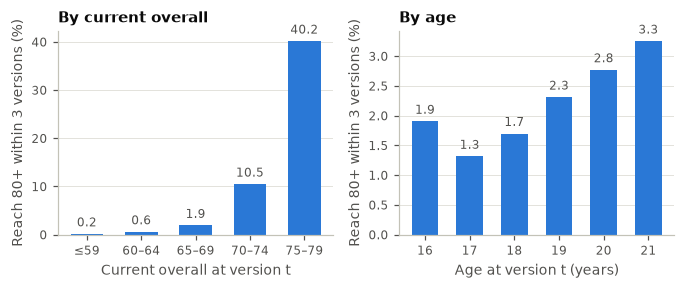

overall,≤59,60–64,65–69,70–74,75–79
rows,8646.00,7192.00,4095.0,1747.00,635.00
positive rate %,0.16,0.58,1.9,10.48,40.16


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(6.3, 2.7))
bands = pd.cut(labelled["overall"], [0, 59, 64, 69, 74, 79], labels=["≤59", "60–64", "65–69", "70–74", "75–79"])
by_band = labelled.groupby(bands, observed=True)["y"].mean() * 100
bars = axes[0].bar(by_band.index.astype(str), by_band.values, width=0.6, color=BLUE)
bar_labels(axes[0], bars, "{:.1f}")
axes[0].set(xlabel="Current overall at version t", ylabel="Reach 80+ within 3 versions (%)", title="By current overall")
by_age = labelled.groupby("age")["y"].mean() * 100
bars = axes[1].bar(by_age.index.astype(str), by_age.values, width=0.6, color=BLUE)
bar_labels(axes[1], bars, "{:.1f}")
axes[1].set(xlabel="Age at version t (years)", ylabel="Reach 80+ within 3 versions (%)", title="By age")
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "fig01_positive_rate")
plt.show()
pd.DataFrame({"rows": labelled.groupby(bands, observed=True).size(), "positive rate %": by_band.round(2)}).T

Four in ten players rated 75 to 79 reach 80+, against about one in 600 of those rated 59 or below. Current overall will clearly be the strongest single predictor.

## 4. Temporal, player-grouped split (T1.7)

| Set | Feature versions | Label window | Used for |
| --- | --- | --- | --- |
| Train | FIFA 15 to 18 | up to FIFA 21 | fitting models |
| Validation | FIFA 19 to 20 | up to FC 23 | fitness score, tuning, early stopping |
| Test | FIFA 21 | FIFA 22 to FC 24 | final results only |

Every player in the test set is removed from train and validation.

In [17]:
labelled["set"] = splits.temporal_group_split(labelled)
splits.check_split(labelled)          # asserts: no test player in train or validation, versions in range
print("split checks pass")
print("rows removed from train / validation because the player is in the test set:", int((labelled["set"] == "removed").sum()))
summary = splits.split_summary(labelled)
summary.round(4)

split checks pass
rows removed from train / validation because the player is in the test set: 2905


,rows,players,positives,positive_rate
set,,,,
train,12148,7064,344,0.0283
val,3974,3099,113,0.0284
test,3288,3288,72,0.0219


In [18]:
train_players = set(labelled.loc[labelled["set"] == "train", "player_id"])
val_players = set(labelled.loc[labelled["set"] == "val", "player_id"])
both = len(train_players & val_players)
print(f"players in both train and validation: {both} of {len(val_players)} validation players ({both / len(val_players):.0%})")

players in both train and validation: 1562 of 3099 validation players (50%)


Half of the validation players also appear in train (in older versions). The plan accepts this; it flatters validation scores a little, and the validation-to-test gap in notebook 05 measures by how much.

Removing test players has a second, less obvious effect: it changes **who is left in validation**.

In [19]:
age_by_set = (labelled[labelled["set"].isin(splits.SETS)]
              .groupby("set")["age"].value_counts(normalize=True).unstack(fill_value=0).loc[list(splits.SETS)] * 100)
age_by_set["mean age"] = labelled[labelled["set"].isin(splits.SETS)].groupby("set")["age"].mean()
age_by_set.round(1)

age,16,17,18,19,20,21,mean age
set,,,,,,,
train,0.3,4.6,14.1,23.8,27.5,29.7,19.6
val,0.2,2.8,7.7,11.3,28.2,49.8,20.1
test,0.6,5.8,13.5,20.8,30.2,29.0,19.6


A player who is eligible in FIFA 21 (the test set) and was also eligible in FIFA 19 or 20 is removed from validation.
The validation rows that remain are players who, by FIFA 21, had turned 22, had reached 80, or had left the game.
Validation is therefore older than test (most rows are aged 20 or 21) and under-represents slow developers.
This follows directly from the plan's rule, so it is kept, logged, and reported as a limitation.

## 5. Leakage columns (T1.8) and the candidate feature pool (T1.9)

In [20]:
print(f"dropped ({len(ft.DROPPED)} columns): identifiers, dates, club and national-team fields, tags, traits,")
print("  position rating strings and goalkeeping attributes")
print(f"set aside, not candidate features ({len(ft.SET_ASIDE)}):", ", ".join(ft.SET_ASIDE))
print("kept for bookkeeping only:", ", ".join(ft.META_COLS))
assert not set(ft.FEATURES) & set(ft.DROPPED + ft.SET_ASIDE + ft.META_COLS)
assert not set(ft.FEATURES) & {"y", "future_max", "overall_t1", "overall_t2", "overall_t3"}
print("no dropped, set-aside or future column is in the feature list")

dropped (53 columns): identifiers, dates, club and national-team fields, tags, traits,
  position rating strings and goalkeeping attributes
set aside, not candidate features (5): potential, value_eur, wage_eur, release_clause_eur, international_reputation
kept for bookkeeping only: player_id, fifa_version, short_name, long_name, player_positions, club_name, league_name, nationality_name
no dropped, set-aside or future column is in the feature list


In [21]:
eligible = data.encode_features(eligible)
labelled = data.encode_features(labelled)
pool = pd.DataFrame({"n": {g: len(f) for g, f in ft.FEATURE_GROUPS.items()},
                     "features": {g: ", ".join(f) for g, f in ft.FEATURE_GROUPS.items()}})
print(f"D = {ft.D} candidate features  ->  2^{ft.D} = {2 ** ft.D:,} possible subsets (about {2 ** ft.D:.2e})")
pd.set_option("display.max_colwidth", 200)
pool

D = 45 candidate features  ->  2^45 = 35,184,372,088,832 possible subsets (about 3.52e+13)


,n,features
Rating,1,overall
Profile,9,"age, height_cm, weight_kg, preferred_foot, weak_foot, skill_moves, league_level, position_group, overall_change"
Face stats,6,"pace, shooting, passing, dribbling, defending, physic"
Attacking,5,"attacking_crossing, attacking_finishing, attacking_heading_accuracy, attacking_short_passing, attacking_volleys"
Skill,5,"skill_dribbling, skill_curve, skill_fk_accuracy, skill_long_passing, skill_ball_control"
Movement,5,"movement_acceleration, movement_sprint_speed, movement_agility, movement_reactions, movement_balance"
Power,5,"power_shot_power, power_jumping, power_stamina, power_strength, power_long_shots"
Mentality,6,"mentality_aggression, mentality_interceptions, mentality_positioning, mentality_vision, mentality_penalties, mentality_composure"
Defending,3,"defending_marking_awareness, defending_standing_tackle, defending_sliding_tackle"


Decisions taken here (all in the decision log):

* **Current `overall` is in the pool.** The list in plan §5 omits it, but hypothesis H3 expects every optimizer to keep it and the plan speaks of "all 45" attributes. It is known at version *t*, so it is not leakage.
* **Position group is one ordinal column** (DEF 0, MID 1, FWD 2) from the first listed position. One-hot encoding would add three bits for one attribute.
* **`overall_change`** is overall(t) − overall(t−1) and is empty when the player was not in the previous version.
* **Missing values** are left as NaN. LightGBM handles them itself; logistic regression and the MLP fill them with the train median inside their pipelines.

In [22]:
missing = labelled[labelled["set"].isin(splits.SETS)].groupby("set")[ft.FEATURES].apply(lambda g: g.isna().mean())
missing = missing.loc[list(splits.SETS), missing.max() > 0]
(missing * 100).round(1)

,league_level,overall_change,mentality_composure
set,,,
train,0.5,60.1,52.3
val,1.1,44.3,0.0
test,0.2,49.7,0.0


Only three features have gaps, and two of them shift between sets:
`overall_change` is always empty in FIFA 15 (there is no FIFA 14 in the data) and `mentality_composure` is empty in FIFA 15 and 16, both of which are train versions.
A tree model can learn "missing" as a signal in train that means something else later, so this is worth remembering when the optimizers choose features.

## 6. Save and freeze (T1.10)

In [23]:
# The saved table holds every eligible row. Rows with an unknown label keep set = "unlabelled"
# so that the sensitivity check in notebook 05 can count them as negatives.
table, counts = data.build_labelled_table(raw)
table["set"] = "unlabelled"
known = ~table["missing_future"]
table.loc[known, "set"] = splits.temporal_group_split(table[known])
splits.check_split(table[table["set"].isin(splits.SETS)])

# the function and the step-by-step path above must give the same table
same = table.loc[known, data.KEYS + ["y", "set"]].reset_index(drop=True)
step = labelled.sort_values(data.KEYS)[data.KEYS + ["y", "set"]].reset_index(drop=True)
assert same.equals(step.astype(same.dtypes.to_dict()))

table.to_parquet(config.LABELLED, index=False)
main = table[table["set"].isin(splits.SETS)]
main[data.KEYS + ["set"]].to_csv(config.SPLIT_IDS, index=False)
print("saved", config.LABELLED.relative_to(ROOT), table.shape)
print("saved", config.SPLIT_IDS.relative_to(ROOT), (len(main), 3))

saved data/processed/labelled.parquet (28817, 67)
saved data/processed/split_ids.csv (19410, 3)


In [24]:
s = splits.split_summary(main)
key_numbers = {
    "rows_raw": counts["rows_raw"],
    "rows_snapshot": counts["rows_snapshot"],
    "rows_goalkeeper_removed": counts["rows_goalkeeper"],
    "rows_eligible": counts["rows_eligible"],
    "rows_missing_future": counts["rows_missing_future"],
    "rows_labelled": counts["rows_labelled"],
    "rows_removed_test_players": int((table["set"] == "removed").sum()),
    "rows_main_analysis": len(main),
    "positive_rate_pct": round(100 * main["y"].mean(), 2),
    "train_rows": int(s.loc["train", "rows"]), "val_rows": int(s.loc["val", "rows"]), "test_rows": int(s.loc["test", "rows"]),
    "train_positives": int(s.loc["train", "positives"]), "val_positives": int(s.loc["val", "positives"]),
    "test_positives": int(s.loc["test", "positives"]),
    "threshold": config.ELITE_THRESHOLD,
    "D": ft.D,
}
pd.Series(key_numbers, name="value").to_csv(TABLES / "data_key_numbers.csv", header=True)
summary.round(4).to_csv(TABLES / "split_summary.csv")
per_version.round(4).to_csv(TABLES / "label_by_version.csv")
pd.Series(key_numbers, name="value", dtype=object).to_frame()

,value
rows_raw,180021
rows_snapshot,180021
rows_goalkeeper_removed,20025
rows_eligible,28817
rows_missing_future,6502
rows_labelled,22315
rows_removed_test_players,2905
rows_main_analysis,19410
positive_rate_pct,2.73
train_rows,12148


## Summary

* 180,021 raw rows, one update per version, so the launch-snapshot rule removes nothing.
* 20,025 goalkeeper rows removed; 28,817 eligible outfield rows (age ≤ 21, overall < 80, FIFA 15 to 21).
* 6,502 eligible rows (22.6%) have no future version and are dropped from the main analysis; 22,315 rows are labelled, 572 of them positive.
* After removing test players from train and validation: 12,148 train rows (344 positives), 3,974 validation rows (113), 3,288 test rows (72). The positive rate is 2.73%, so a random ranking scores a PR-AUC of about 0.03.
* Threshold 80 and age limit 21 are final. D = 45 candidate features.

The data design is frozen here (`git tag data-frozen`). Nothing in it changes after a model has been scored.